In [168]:
"""
Mortality Prediction with Chronos-2 Embeddings
Optimized: Sample windows first, then generate embeddings
"""
import matplotlib.pyplot as plt
import scipy.io
import torch
import numpy as np
import pandas as pd
from chronos import Chronos2Pipeline
import pickle as pl
import glob
import traceback
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from torchvision.ops import sigmoid_focal_loss

In [169]:
# ============================================================================
# CONSTANTS
# ============================================================================

CONTEXT_SIZE_HOURS = 80
CONTEXT_SIZE_SECONDS = CONTEXT_SIZE_HOURS * 3600  # 288,000 seconds
WINDOW_SIZE_SECONDS = 300  # 5 minutes
NUM_WINDOWS = CONTEXT_SIZE_SECONDS // WINDOW_SIZE_SECONDS  # 960 windows

# Thresholds for prediction
THRESHOLDS_DAYS = [3, 5, 7]
THRESHOLDS_SECONDS = [d * 86400 for d in THRESHOLDS_DAYS]

# Overlap configuration (for Step 1: metadata generation)
OVERLAP_PERCENTAGE_NON_NICU = 0.0   # No overlap
OVERLAP_PERCENTAGE_NICU = 0.90      # 90% overlap

# ✅ UPDATED: Separate max windows for metadata generation
MAX_METADATA_WINDOWS_NON_NICU = 15   # Keep same
MAX_METADATA_WINDOWS_NICU = 200      # Keep same

# ✅ UPDATED: Sampling configuration (BALANCED)
NUM_SAMPLE_WINDOWS_NON_NICU = 5      # ← DECREASED from 10 (reduce label 0)
NUM_SAMPLE_WINDOWS_NICU = 100        # Keep same

# ✅ NEW: Bias toward later windows (near death) for NICU
NICU_LATE_WINDOW_BIAS = 0.7  # 70% of samples from later half of timeline

In [170]:
# ============================================================================
# HELPER FUNCTIONS (UNCHANGED)
# ============================================================================

def extract_raw_timeseries(mat_file_path, start_time, context_size):
    """Extract raw HR and SPO2 time series data from MATLAB file"""
    try:
        mat_data = scipy.io.loadmat(mat_file_path)
    except Exception as e:
        print(f"Error loading {mat_file_path}: {e}")
        return None
    
    birth_time = mat_data['pdata'][0][1]
    age_at_death = mat_data['pdata'][0][-1]
    death_ts = age_at_death * 86400 if not np.isnan(age_at_death) else None
    
    hr_cols = mat_data['vdata'][:,0]
    spo2_cols = mat_data['vdata'][:,2]
    timestamps = mat_data['vt'].flatten()
    
    end_time = start_time + context_size
    time_mask = (timestamps >= start_time) & (timestamps < end_time)
    valid_mask = ~np.isnan(hr_cols) & ~np.isnan(spo2_cols)
    final_mask = time_mask & valid_mask
    
    timestamps_valid = timestamps[final_mask]
    hr_valid = hr_cols[final_mask]
    spo2_valid = spo2_cols[final_mask]
    
    if len(timestamps_valid) == 0:
        return None
    
    return {
        'timestamps': timestamps_valid,
        'hr_raw': hr_valid,
        'spo2_raw': spo2_valid,
        'birth_time': birth_time,
        'death_ts': death_ts,
        'start_time': start_time,
        'context_size': context_size
    }

def create_windowed_features_from_raw(raw_data, window_size):
    """Convert raw time series into fixed-size windowed features"""
    timestamps = raw_data['timestamps']
    hr_raw = raw_data['hr_raw']
    spo2_raw = raw_data['spo2_raw']
    start_time = raw_data['start_time']
    context_size = raw_data['context_size']
    
    window_indices = np.floor((timestamps - start_time) / window_size).astype(int)
    num_windows = int(np.ceil(context_size / window_size))
    
    hr_windows = np.full(num_windows, np.nan)
    spo2_windows = np.full(num_windows, np.nan)
    
    for idx in range(num_windows):
        mask = window_indices == idx
        if np.any(mask):
            hr_windows[idx] = np.mean(hr_raw[mask])
            spo2_windows[idx] = np.mean(spo2_raw[mask])
    
    return hr_windows, spo2_windows

def create_windowed_features(mat_file_path, start_time, context_size, window_size):
    """Convenience function: combines raw extraction + windowing"""
    raw_data = extract_raw_timeseries(mat_file_path, start_time, context_size)
    if raw_data is None:
        return None
    return create_windowed_features_from_raw(raw_data, window_size)

def prepare_chronos_input(hr_windows, spo2_windows):
    """Prepare windowed data for Chronos model input"""
    hr_clean = np.where(
        np.isnan(hr_windows), 
        np.nanmean(hr_windows) if not np.all(np.isnan(hr_windows)) else 0, 
        hr_windows
    ).astype(np.float32)
    
    spo2_clean = np.where(
        np.isnan(spo2_windows), 
        np.nanmean(spo2_windows) if not np.all(np.isnan(spo2_windows)) else 0, 
        spo2_windows
    ).astype(np.float32)
    
    hr_tensor = torch.tensor(hr_clean, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    spo2_tensor = torch.tensor(spo2_clean, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    
    context = torch.cat([hr_tensor, spo2_tensor], dim=0)
    return context

def get_chronos_embedding(chronos_input, pipeline):
    """Generate embedding from Chronos model"""
    with torch.no_grad():
        embeddings, _ = pipeline.embed(chronos_input)
    
    hr_emb = embeddings[0][0][-1].float()
    spo2_emb = embeddings[1][0][-1].float()
    combined_embedding = torch.cat([hr_emb, spo2_emb], dim=0).cpu().numpy()
    
    return combined_embedding

def get_embedding(hr_windows, spo2_windows, pipeline):
    """Convenience function: combines preparation + embedding generation"""
    chronos_input = prepare_chronos_input(hr_windows, spo2_windows)
    return get_chronos_embedding(chronos_input, pipeline)


def create_window_key(mat_file, window_start, window_end):
    """Create unique key: baby_id_window_start_window_end"""
    baby_id = mat_file.split('/')[-1].replace('.mat', '')
    return f"{baby_id}_{int(window_start)}_{int(window_end)}"


def get_or_generate_embedding(mat_file, window_start, window_end, pipeline, cache):
    """Get from cache or generate new"""
    key = create_window_key(mat_file, window_start, window_end)
    
    if key in cache:
        return cache[key], True  # From cache
    
    # Generate new
    try:
        result = create_windowed_features(mat_file, window_start, 
                                         CONTEXT_SIZE_SECONDS, WINDOW_SIZE_SECONDS)
        if result is not None:
            embedding = get_embedding(result[0], result[1], pipeline)
            cache[key] = embedding
            return embedding, False  # Newly generated
    except:
        pass
    
    return None, False

# ...existing code...


In [171]:
# ============================================================================
# STEP 1: GENERATE WINDOW METADATA (UNIFORMLY SPACED IF CAPPING)
# ============================================================================

def generate_window_metadata_for_baby(mat_file_path, overlap_percentage, max_windows):
    """
    Generate window metadata with UNIFORM SPACING when capping.
    
    Two cases:
    1. num_possible ≤ max_windows: Generate ALL windows
    2. num_possible > max_windows: Uniformly sample max_windows across timeline
    """
    try:
        mat_data = scipy.io.loadmat(mat_file_path)
    except Exception as e:
        return pd.DataFrame()
    
    birth_time = mat_data['pdata'][0][1]
    age_at_death = mat_data['pdata'][0][-1]
    death_ts = age_at_death * 86400 if not np.isnan(age_at_death) else np.nan
    
    if np.isnan(birth_time):
        return pd.DataFrame()
    
    timestamps = mat_data['vt'].flatten()
    last_ts = timestamps[-1].item()
    
    baby_type = 'NICU' if not np.isnan(death_ts) else 'NON_NICU'
    baby_id = mat_file_path.split('/')[-1].replace('.mat', '')
    
    available_time = last_ts - birth_time
    
    if available_time < CONTEXT_SIZE_SECONDS:
        return pd.DataFrame()
    
    # Calculate step size based on overlap
    step_size = CONTEXT_SIZE_SECONDS * (1 - overlap_percentage)
    
    # Calculate total possible windows
    num_possible_windows = int((available_time - CONTEXT_SIZE_SECONDS) / step_size) + 1
    
    # ✅ SIMPLE LOGIC: Take all if ≤ max, uniformly sample if > max
    windows = []
    
    if num_possible_windows <= max_windows:
        # Case 1: Take ALL windows
        for i in range(num_possible_windows):
            window_start = birth_time + i * step_size
            window_end = window_start + CONTEXT_SIZE_SECONDS
            
            if window_end <= last_ts:
                windows.append({
                    'mat_file': mat_file_path,
                    'baby_id': baby_id,
                    'window_start': window_start,
                    'window_end': window_end,
                    'baby_type': baby_type,
                    'death_time': death_ts,
                    'birth_time': birth_time
                })
    else:
        # Case 2: Uniformly sample max_windows
        indices = np.linspace(0, num_possible_windows - 1, max_windows, dtype=int)
        
        for idx in indices:
            window_start = birth_time + idx * step_size
            window_end = window_start + CONTEXT_SIZE_SECONDS
            
            if window_end <= last_ts:
                windows.append({
                    'mat_file': mat_file_path,
                    'baby_id': baby_id,
                    'window_start': window_start,
                    'window_end': window_end,
                    'baby_type': baby_type,
                    'death_time': death_ts,
                    'birth_time': birth_time
                })
    
    return pd.DataFrame(windows)


def generate_all_window_metadata(nicu_files, non_nicu_files):
    """Generate window metadata with separate limits per baby type"""
    print("\n" + "="*80)
    print(" "*20 + "STEP 1: GENERATING WINDOW METADATA")
    print(" "*15 + "(Uniformly Spaced, Threshold-Independent)")
    print("="*80 + "\n")
    
    all_metadata = []
    
    # Non-NICU babies
    print(f"Processing {len(non_nicu_files)} Non-NICU babies...")
    print(f"  Overlap: {OVERLAP_PERCENTAGE_NON_NICU*100:.0f}%")
    print(f"  Max metadata windows: {MAX_METADATA_WINDOWS_NON_NICU}\n")
    
    for i, file_path in enumerate(non_nicu_files):
        baby_id = file_path.split('/')[-1].replace('.mat', '')
        
        if (i + 1) % 20 == 0 or i + 1 == len(non_nicu_files):
            print(f"  Progress: {i+1}/{len(non_nicu_files)} babies")
        
        try:
            df = generate_window_metadata_for_baby(
                file_path, 
                overlap_percentage=OVERLAP_PERCENTAGE_NON_NICU,
                max_windows=MAX_METADATA_WINDOWS_NON_NICU
            )
            all_metadata.append(df)
        except Exception as e:
            print(f"  ✗ Error with baby {baby_id}: {str(e)}")
    
    # NICU babies
    print(f"\nProcessing {len(nicu_files)} NICU babies...")
    print(f"  Overlap: {OVERLAP_PERCENTAGE_NICU*100:.0f}%")
    print(f"  Max metadata windows: {MAX_METADATA_WINDOWS_NICU}\n")
    
    for i, file_path in enumerate(nicu_files):
        baby_id = file_path.split('/')[-1].replace('.mat', '')
        
        if (i + 1) % 10 == 0 or i + 1 == len(nicu_files):
            print(f"  Progress: {i+1}/{len(nicu_files)} babies")
        
        try:
            df = generate_window_metadata_for_baby(
                file_path, 
                overlap_percentage=OVERLAP_PERCENTAGE_NICU,
                max_windows=MAX_METADATA_WINDOWS_NICU
            )
            all_metadata.append(df)
        except Exception as e:
            print(f"  ✗ Error with baby {baby_id}: {str(e)}")
    
    # Combine all metadata
    metadata_df = pd.concat(all_metadata, ignore_index=True)
    
    print(f"\n{'='*80}")
    print(f"✓ Total metadata windows: {len(metadata_df)}")
    print(f"  Non-NICU: {len(metadata_df[metadata_df['baby_type'] == 'NON_NICU'])}")
    print(f"  NICU: {len(metadata_df[metadata_df['baby_type'] == 'NICU'])}")
    print(f"{'='*80}\n")
    
    # Save metadata
    metadata_df.to_pickle('window_metadata.pkl')
    print("✓ Saved: window_metadata.pkl\n")
    
    return metadata_df


In [172]:
# ============================================================================
# STEP 2: SAMPLE WINDOWS (BIASED TOWARD LATER WINDOWS FOR NICU)
# ============================================================================

def sample_windows_once(metadata_df):
    """
    Sample windows with BIAS toward later windows for NICU babies.
    
    Strategy:
    1. NON-NICU: Uniform sampling (reduced count)
    2. NICU: Biased sampling - more from later windows (near death)
    """
    print("\n" + "="*80)
    print(" "*15 + "STEP 2: SAMPLING WINDOWS (BIASED FOR BALANCE)")
    print("="*80 + "\n")
    
    all_sampled_windows = []
    
    # === NON-NICU BABIES (Reduced sampling) ===
    print("Sampling Non-NICU babies (REDUCED for balance)...")
    non_nicu_babies = metadata_df[metadata_df['baby_type'] == 'NON_NICU']['baby_id'].unique()
    
    non_nicu_count = 0
    for baby_id in non_nicu_babies:
        baby_windows = metadata_df[metadata_df['baby_id'] == baby_id]
        n_available = len(baby_windows)
        n_needed = NUM_SAMPLE_WINDOWS_NON_NICU
        
        if n_available <= n_needed:
            # Take ALL windows
            selected = baby_windows.copy()
        else:
            # Uniformly sample
            indices = np.linspace(0, n_available - 1, n_needed, dtype=int)
            selected = baby_windows.iloc[indices].copy()
        
        all_sampled_windows.append(selected)
        non_nicu_count += len(selected)
    
    print(f"  ✓ Sampled {non_nicu_count} windows from {len(non_nicu_babies)} Non-NICU babies")
    print(f"    Average: {non_nicu_count/len(non_nicu_babies):.1f} windows/baby\n")
    
    # === NICU BABIES (BIASED toward later windows) ===
    print("Sampling NICU babies (BIASED toward later windows)...")
    nicu_babies = metadata_df[metadata_df['baby_type'] == 'NICU']['baby_id'].unique()
    
    nicu_count = 0
    early_count = 0
    late_count = 0
    
    for baby_id in nicu_babies:
        baby_windows = metadata_df[metadata_df['baby_id'] == baby_id].sort_values('window_start')
        n_available = len(baby_windows)
        n_needed = NUM_SAMPLE_WINDOWS_NICU
        
        if n_available <= n_needed:
            # Take ALL windows
            selected = baby_windows.copy()
            all_sampled_windows.append(selected)
            nicu_count += len(selected)
        else:
            # ✅ BIASED SAMPLING: More from later half
            midpoint = len(baby_windows) // 2
            early_windows = baby_windows.iloc[:midpoint]
            late_windows = baby_windows.iloc[midpoint:]
            
            # Calculate split (70% late, 30% early)
            n_late = int(n_needed * NICU_LATE_WINDOW_BIAS)
            n_early = n_needed - n_late
            
            selected_windows = []
            
            # Sample from early windows (uniformly)
            if len(early_windows) > 0 and n_early > 0:
                n_early_actual = min(n_early, len(early_windows))
                indices = np.linspace(0, len(early_windows) - 1, n_early_actual, dtype=int)
                selected_windows.append(early_windows.iloc[indices])
                early_count += n_early_actual
            
            # Sample from late windows (uniformly)
            if len(late_windows) > 0 and n_late > 0:
                n_late_actual = min(n_late, len(late_windows))
                indices = np.linspace(0, len(late_windows) - 1, n_late_actual, dtype=int)
                selected_windows.append(late_windows.iloc[indices])
                late_count += n_late_actual
            
            # Combine
            if selected_windows:
                selected = pd.concat(selected_windows)
                all_sampled_windows.append(selected)
                nicu_count += len(selected)
    
    print(f"  ✓ Sampled {nicu_count} windows from {len(nicu_babies)} NICU babies")
    print(f"    Average: {nicu_count/len(nicu_babies):.1f} windows/baby")
    print(f"    Early windows: {early_count} ({early_count/nicu_count*100:.1f}%)")
    print(f"    Late windows: {late_count} ({late_count/nicu_count*100:.1f}%)\n")
    
    # Combine all sampled windows
    sampled_windows_df = pd.concat(all_sampled_windows, ignore_index=True)
    
    print(f"{'='*80}")
    print(f"✓ Total sampled windows: {len(sampled_windows_df)}")
    print(f"  Non-NICU: {len(sampled_windows_df[sampled_windows_df['baby_type'] == 'NON_NICU'])}")
    print(f"  NICU: {len(sampled_windows_df[sampled_windows_df['baby_type'] == 'NICU'])}")
    print(f"  Bias applied: {NICU_LATE_WINDOW_BIAS*100:.0f}% late, {(1-NICU_LATE_WINDOW_BIAS)*100:.0f}% early")
    print(f"{'='*80}\n")
    
    return sampled_windows_df


def assign_labels_for_all_thresholds(sampled_windows_df):
    """
    Assign labels for ALL thresholds to the SAME windows.
    This creates multiple labeled versions of the same window set.
    """
    print("\n" + "="*80)
    print(" "*15 + "ASSIGNING LABELS FOR ALL THRESHOLDS")
    print(" "*20 + "(Same windows, different labels)")
    print("="*80 + "\n")
    
    all_labeled_data = []
    
    for threshold_days, threshold_seconds in zip(THRESHOLDS_DAYS, THRESHOLDS_SECONDS):
        print(f"Assigning labels for {threshold_days}-day threshold...")
        
        df = sampled_windows_df.copy()
        
        # Non-NICU: Always label 0
        df.loc[df['baby_type'] == 'NON_NICU', 'label'] = 0
        
        # NICU: Label based on threshold
        nicu_mask = df['baby_type'] == 'NICU'
        threshold_start = df.loc[nicu_mask, 'death_time'] - threshold_seconds
        
        df.loc[nicu_mask, 'label'] = (
            df.loc[nicu_mask, 'window_end'] > threshold_start
        ).astype(int)
        
        # Add threshold identifier
        df['threshold_days'] = threshold_days
        
        all_labeled_data.append(df)
        
        # Statistics
        n_total = len(df)
        n_label_0 = (df['label'] == 0).sum()
        n_label_1 = (df['label'] == 1).sum()
        
        print(f"  ✓ Total: {n_total}, Label 0: {n_label_0}, Label 1: {n_label_1}")
        print(f"    Class balance: {n_label_0/n_total*100:.1f}% / {n_label_1/n_total*100:.1f}%\n")
    
    # Combine all thresholds
    all_labeled_df = pd.concat(all_labeled_data, ignore_index=False)
    
    # Save
    all_labeled_df.to_pickle('sampled_windows_all_thresholds.pkl')
    print("✓ Saved: sampled_windows_all_thresholds.pkl")
    
    # Also save unique windows for embedding generation
    unique_windows_df = sampled_windows_df.copy()
    unique_windows_df.to_pickle('windows_to_embed.pkl')
    print("✓ Saved: windows_to_embed.pkl")
    
    print(f"\n{'='*80}")
    print(f"✓ Total labeled entries: {len(all_labeled_df)}")
    print(f"✓ Unique windows: {len(unique_windows_df)}")
    print(f"  (Each window appears {len(THRESHOLDS_DAYS)} times with different labels)")
    print(f"{'='*80}\n")
    
    return all_labeled_df, unique_windows_df


def sample_and_label_all_thresholds(metadata_df):
    """
    Complete function: Sample once, label for all thresholds.
    """
    # Step 1: Sample windows (threshold-independent)
    sampled_windows_df = sample_windows_once(metadata_df)
    
    # Step 2: Assign labels for all thresholds
    all_labeled_df, unique_windows_df = assign_labels_for_all_thresholds(sampled_windows_df)
    
    return all_labeled_df, unique_windows_df

In [173]:
# ============================================================================
# STEP 3: GENERATE EMBEDDINGS FOR SAMPLED WINDOWS ONLY
# ============================================================================

def generate_embeddings_for_windows(windows_df, pipeline):
    """Generate embeddings with caching - stores by global key"""
    print("\n" + "="*80)
    print(" "*15 + "STEP 3: GENERATING EMBEDDINGS (WITH CACHING)")
    print("="*80 + "\n")
    
    # Load existing cache
    import os
    if os.path.exists('embeddings_global.pkl'):
        with open('embeddings_global.pkl', 'rb') as f:
            cache = pl.load(f)
        print(f"Loaded {len(cache)} cached embeddings")
    else:
        cache = {}
        print("Starting fresh cache")
    
    initial_size = len(cache)
    cache_hits = 0
    cache_misses = 0
    
    # Process windows
    total = len(windows_df)
    for i, (idx, row) in enumerate(windows_df.iterrows()):
        embedding, was_cached = get_or_generate_embedding(
            row['mat_file'], 
            row['window_start'], 
            row['window_end'],
            pipeline, 
            cache
        )
        
        if was_cached:
            cache_hits += 1
        else:
            cache_misses += 1
        
        # Progress
        if (i + 1) % 50 == 0 or (i + 1) == total:
            print(f"  {i+1}/{total} | Cache: {cache_hits}, New: {cache_misses}")
    
    # Summary
    print(f"\n✓ Processed {total} windows")
    print(f"  Cache hits: {cache_hits} ({cache_hits/total*100:.1f}%)")
    print(f"  New: {cache_misses}")
    print(f"  Global cache: {initial_size} → {len(cache)} "
          f"(+{len(cache)-initial_size})\n")
    
    # Save global cache
    with open('embeddings_global.pkl', 'wb') as f:
        pl.dump(cache, f)
    
    print("✓ Saved: embeddings_global.pkl\n")
    
    return cache  # Return the cache itself

In [174]:
# ============================================================================
# STEP 4: PREPARE DATA FOR TRAINING (EFFICIENT - STORE KEYS NOT INDICES)
# ============================================================================

def prepare_training_data_for_threshold(threshold_days, embeddings_cache=None):
    """
    Prepare data for one threshold WITHOUT duplicating embeddings.
    Stores global embedding keys + labels (not DataFrame indices).
    """
    print(f"\nPreparing {threshold_days}-day threshold...")
    
    # Load global cache if not provided
    if embeddings_cache is None:
        with open('embeddings_global.pkl', 'rb') as f:
            embeddings_cache = pl.load(f)
    
    # Load labeled data
    sampled_all = pd.read_pickle('sampled_windows_all_thresholds.pkl')
    threshold_data = sampled_all[sampled_all['threshold_days'] == threshold_days]
    
    # Collect keys and labels
    embedding_keys = []
    labels = []
    
    for idx, row in threshold_data.iterrows():
        # Create global key
        key = create_window_key(row['mat_file'], row['window_start'], row['window_end'])
        
        if key in embeddings_cache:
            embedding_keys.append(key)
            labels.append(int(row['label']))
    
    print(f"  ✓ {len(embedding_keys)} samples (L0:{labels.count(0)}, L1:{labels.count(1)})")
    
    # Save ONLY keys and labels (not embeddings!)
    with open(f'labels_{threshold_days}d.pkl', 'wb') as f:
        pl.dump({'embedding_keys': embedding_keys, 'labels': labels}, f)
    
    print(f"  ✓ Saved: labels_{threshold_days}d.pkl (~{(len(embedding_keys) * 100) / 1024:.2f} KB)")
    
    # Return actual embeddings for immediate training use
    embeddings = [embeddings_cache[key] for key in embedding_keys]
    
    return embeddings, labels


def load_training_data_for_threshold(threshold_days):
    """
    Load training data by combining labels file + global embeddings.
    """
    print(f"\nLoading {threshold_days}-day threshold from saved files...")
    
    # Load keys and labels (tiny file)
    with open(f'labels_{threshold_days}d.pkl', 'rb') as f:
        data = pl.load(f)
    
    # Load embeddings (shared across all thresholds)
    with open('embeddings_global.pkl', 'rb') as f:
        embeddings_cache = pl.load(f)
    
    # Reconstruct embeddings list
    embeddings = [embeddings_cache[key] for key in data['embedding_keys']]
    labels = data['labels']
    
    print(f"  ✓ Loaded {len(embeddings)} samples (L0:{labels.count(0)}, L1:{labels.count(1)})")
    
    return embeddings, labels


In [175]:
# ============================================================================
# STEP 5: TRAIN CLASSIFIER (BINARY WITH SIGMOID FOCAL LOSS)
# ============================================================================

class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = [torch.FloatTensor(e) for e in embeddings]
        self.labels = torch.FloatTensor(labels)  # ← Float for binary
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.embeddings[idx], self.labels[idx]


class Classifier(nn.Module):
    """Binary classifier - outputs 1 raw logit (NO sigmoid)"""
    def __init__(self, dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden // 2, 1)  # ← 1 output for binary classification
        )
    
    def forward(self, x):
        return self.net(x.view(x.size(0), -1)).squeeze()  # ← Raw logits


def train_epoch(model, loader, optimizer, device, use_focal_loss=False, alpha=0.25, gamma=2.0):
    """Train one epoch"""
    model.train()
    total_loss = 0
    
    for embs, labels in loader:
        embs, labels = embs.to(device), labels.to(device)
        optimizer.zero_grad()
        
        logits = model(embs)  # Raw logits
        
        if use_focal_loss:
            # sigmoid_focal_loss applies sigmoid internally
            loss = sigmoid_focal_loss(logits, labels, alpha=alpha, gamma=gamma, reduction='mean')
        else:
            # BCEWithLogitsLoss also applies sigmoid internally
            loss = nn.BCEWithLogitsLoss()(logits, labels)
        
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(loader)


def validate(model, loader, device):
    """Validate model"""
    model.eval()
    preds, lbls, probs = [], [], []
    
    with torch.no_grad():
        for embs, labels in loader:
            embs, labels = embs.to(device), labels.to(device)
            logits = model(embs)  # Raw logits
            
            # Apply sigmoid for inference
            probs_batch = torch.sigmoid(logits).cpu().numpy()
            preds_batch = (probs_batch > 0.5).astype(int)
            
            probs.extend(probs_batch)
            preds.extend(preds_batch)
            lbls.extend(labels.cpu().numpy())
    
    return {
        'accuracy': accuracy_score(lbls, preds),
        'precision': precision_score(lbls, preds, zero_division=0),
        'recall': recall_score(lbls, preds, zero_division=0),
        'f1': f1_score(lbls, preds, zero_division=0),
        'auc': roc_auc_score(lbls, probs) if len(set(lbls)) > 1 else 0
    }


def k_fold_cv(embeddings, labels, k=5, epochs=50, batch_size=32, lr=0.001, 
              device='cpu', use_focal_loss=False, alpha=0.25, gamma=2.0):
    """K-Fold CV with optional focal loss"""
    if len(embeddings) == 0:
        print("No embeddings to train on!")
        return None, None, None
    
    embeddings = np.array(embeddings)
    labels = np.array(labels)
    dim = embeddings[0].flatten().shape[0]
    
    # Auto-compute alpha if None
    if use_focal_loss and alpha is None:
        n_neg = (labels == 0).sum()
        alpha = n_neg / len(labels)
    
    loss_type = f"Focal Loss (α={alpha:.3f}, γ={gamma})" if use_focal_loss else "Binary CE"
    print(f"\n{'='*80}")
    print(f"K-Fold CV with {loss_type}")
    print(f"Samples: {len(labels)}, Folds: {k}, Embedding dim: {dim}")
    print(f"Class distribution: Label 0: {(labels==0).sum()}, Label 1: {(labels==1).sum()}")
    print(f"{'='*80}\n")
    
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    fold_metrics = []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(embeddings, labels)):
        print(f"Fold {fold+1}/{k}...", end=" ")
        
        train_data = EmbeddingDataset(embeddings[train_idx], labels[train_idx])
        val_data = EmbeddingDataset(embeddings[val_idx], labels[val_idx])
        train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_data, batch_size=batch_size)
        
        model = Classifier(dim).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
        for _ in range(epochs):
            train_epoch(model, train_loader, optimizer, device, 
                       use_focal_loss=use_focal_loss, alpha=alpha, gamma=gamma)
        
        metrics = validate(model, val_loader, device)
        fold_metrics.append(metrics)
        print(f"Acc: {metrics['accuracy']:.4f}, F1: {metrics['f1']:.4f}, "
              f"Recall: {metrics['recall']:.4f}, AUC: {metrics['auc']:.4f}")
    
    avg = {k: np.mean([f[k] for f in fold_metrics]) for k in fold_metrics[0]}
    std = {k: np.std([f[k] for f in fold_metrics]) for k in fold_metrics[0]}
    
    print(f"\n{'='*80}")
    print(f"AVERAGE METRICS ({loss_type})")
    print('─'*80)
    for k in avg:
        print(f"{k.capitalize():12s}: {avg[k]:.4f} ± {std[k]:.4f}")
    print('='*80)
    
    return avg, std, fold_metrics

In [176]:
# ============================================================================
# COMPLETE PIPELINE (UPDATED - USE GLOBAL KEYS)
# ============================================================================

def run_complete_pipeline(use_focal_loss=False, gamma=2.0):
    """
    Complete pipeline with optional Focal Loss.
    NOW USES GLOBAL EMBEDDING KEYS (not DataFrame indices).
    
    Args:
        use_focal_loss: If True, use Focal Loss instead of Cross-Entropy
        gamma: Focal loss gamma parameter (default 2.0)
    """
    loss_name = f"Focal Loss (γ={gamma})" if use_focal_loss else "Cross-Entropy"
    print("\n" + "="*100)
    print(" "*15 + f"MORTALITY PREDICTION PIPELINE WITH {loss_name.upper()}")
    print("="*100 + "\n")
    
    # Load files
    with open('valid_summary_dic.pkl', 'rb') as f:
        valid_summary_dic = pl.load(f)
    
    nicu_mask = valid_summary_dic['indicator_vector'] == 1
    nicu_baby_ids = set(valid_summary_dic['baby_id'][nicu_mask])
    non_nicu_baby_ids = set(valid_summary_dic['baby_id'][~nicu_mask])
    
    all_mat_files = sorted(glob.glob('./download/Vitals/*.mat'))
    nicu_files = [f for f in all_mat_files if f.split('/')[-1] in nicu_baby_ids]
    non_nicu_files = [f for f in all_mat_files if f.split('/')[-1] in non_nicu_baby_ids]
    
    print(f"✓ {len(nicu_files)} NICU files")
    print(f"✓ {len(non_nicu_files)} Non-NICU files\n")
    
    # STEP 1: Metadata
    import os
    if os.path.exists('window_metadata.pkl'):
        metadata_df = pd.read_pickle('window_metadata.pkl')
        print(f"✓ Loaded metadata: {len(metadata_df)} windows\n")
    else:
        metadata_df = generate_all_window_metadata(nicu_files, non_nicu_files)
    
    # STEP 2: Sample windows
    if os.path.exists('windows_to_embed.pkl'):
        unique_windows_df = pd.read_pickle('windows_to_embed.pkl')
        print(f"✓ Loaded sampled windows: {len(unique_windows_df)}\n")
    else:
        _, unique_windows_df = sample_and_label_all_thresholds(metadata_df)
    
    # # STEP 3: Generate embeddings (returns global cache)
    # if os.path.exists('embeddings_global.pkl'):
    #     with open('embeddings_global.pkl', 'rb') as f:
    #         embeddings_cache = pl.load(f)
    #     print(f"✓ Loaded global embeddings cache: {len(embeddings_cache)} embeddings\n")
    # else:
    #     pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", 
    #                                                 device_map="cpu", 
    #                                                 dtype=torch.bfloat16)
    #     embeddings_cache = generate_embeddings_for_windows(unique_windows_df, pipeline)
    
    # # STEP 4-5: Train each threshold
    # for threshold_days in THRESHOLDS_DAYS:
    #     print("\n" + "="*100)
    #     print(f" "*30 + f"THRESHOLD: {threshold_days} DAYS ({loss_name})")
    #     print("="*100)
        
    #     # Prepare data (saves labels_Xd.pkl, returns embeddings for training)
    #     embeddings, labels = prepare_training_data_for_threshold(threshold_days, embeddings_cache)
        
    #     # Train with chosen loss
    #     avg, std, fold_metrics = k_fold_cv(
    #         embeddings, labels, 
    #         k=5, epochs=50, batch_size=32, lr=0.001, device='cpu',
    #         use_focal_loss=use_focal_loss, gamma=gamma
    #     )
        
    #     # Save results with appropriate suffix
    #     suffix = 'focal' if use_focal_loss else 'ce'
    #     filename = f'results_{threshold_days}d_{suffix}.pkl'
    #     with open(filename, 'wb') as f:
    #         pl.dump({
    #             'avg': avg, 
    #             'std': std, 
    #             'fold_metrics': fold_metrics,
    #             'loss_type': loss_name,
    #             'gamma': gamma if use_focal_loss else None
    #         }, f)
    #     print(f"\n✓ Saved: {filename}")
    
    # print("\n" + "="*100)
    # print(" "*30 + "✓ PIPELINE COMPLETE")
    # print("="*100 + "\n")

In [ ]:
# run_complete_pipeline(use_focal_loss=False)
run_complete_pipeline(use_focal_loss=True, gamma=3.0) 


               MORTALITY PREDICTION PIPELINE WITH FOCAL LOSS (Γ=3.0)

✓ 186 NICU files
✓ 4841 Non-NICU files


                    STEP 1: GENERATING WINDOW METADATA
               (Uniformly Spaced, Threshold-Independent)

Processing 4841 Non-NICU babies...
  Overlap: 0%
  Max metadata windows: 15

  Progress: 20/4841 babies
  Progress: 40/4841 babies
  Progress: 60/4841 babies
  Progress: 80/4841 babies
  Progress: 100/4841 babies
  Progress: 120/4841 babies
  Progress: 140/4841 babies
  Progress: 160/4841 babies
  Progress: 180/4841 babies
  Progress: 200/4841 babies
  Progress: 220/4841 babies
  Progress: 240/4841 babies
  Progress: 260/4841 babies
  Progress: 280/4841 babies
  Progress: 300/4841 babies
  Progress: 320/4841 babies
  Progress: 340/4841 babies
  Progress: 360/4841 babies
  Progress: 380/4841 babies
  Progress: 400/4841 babies
  Progress: 420/4841 babies
  Progress: 440/4841 babies
  Progress: 460/4841 babies
  Progress: 480/4841 babies
  Progress: 500/4841 babies
  

### Window generation analysis 

In [154]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_with_chronos/window_metadata.pkl','rb') as f:
    df = pl.load(f)

In [155]:
df[ df["baby_id"] == "NICU_8771_vitals"]

,mat_file,baby_id,window_start,window_end,baby_type,death_time,birth_time
29050,./download/Vitals/NICU_8771_vitals.mat,NICU_8771_vitals,0.0,288000.0,NON_NICU,NaN,0.0
29051,./download/Vitals/NICU_8771_vitals.mat,NICU_8771_vitals,288000.0,576000.0,NON_NICU,NaN,0.0


In [156]:
nicu_values_list = list(df[df["baby_type"]=="NICU"].groupby('baby_id').size())
non_nicu_values_list = list(df[df["baby_type"]=="NON_NICU"].groupby('baby_id').size())

In [157]:
print(sum([MAX_METADATA_WINDOWS_NICU==i for i in nicu_values_list])/len(nicu_values_list))
print(sum([MAX_METADATA_WINDOWS_NON_NICU==i for i in non_nicu_values_list])/len(non_nicu_values_list))

0.15671641791044777
0.010747551946501075


(array([0.02985075, 0.08208955, 0.10447761, 0.12686567, 0.14179104,
        0.17164179, 0.17910448, 0.20895522, 0.2238806 , 0.25373134,
        0.26119403, 0.28358209, 0.32089552, 0.34328358, 0.36567164,
        0.3880597 , 0.39552239, 0.40298507, 0.41044776, 0.43283582,
        0.43283582, 0.44029851, 0.44776119, 0.44776119, 0.44776119,
        0.44776119, 0.46268657, 0.46268657, 0.46268657, 0.46268657,
        0.48507463, 0.49253731, 0.5       , 0.5       , 0.50746269,
        0.51492537, 0.51492537, 0.51492537, 0.51492537, 0.51492537,
        0.51492537, 0.52238806, 0.52238806, 0.52238806, 0.52238806,
        0.52985075, 0.52985075, 0.52985075, 0.52985075, 0.53731343,
        0.53731343, 0.54477612, 0.54477612, 0.54477612, 0.54477612,
        0.55223881, 0.55223881, 0.55223881, 0.55970149, 0.56716418,
        0.56716418, 0.56716418, 0.56716418, 0.57462687, 0.58955224,
        0.58955224, 0.58955224, 0.59701493, 0.59701493, 0.59701493,
        0.60447761, 0.60447761, 0.6119403 , 0.61

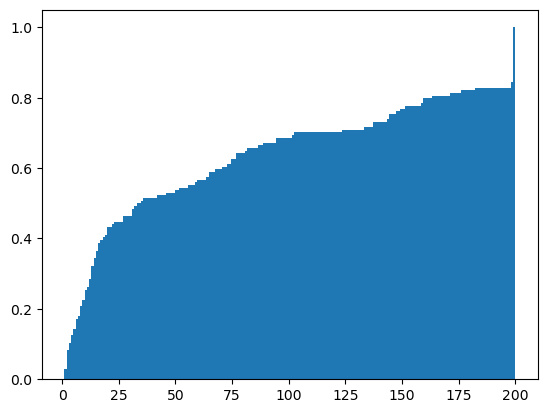

In [158]:
plt.hist(nicu_values_list,density=True,bins=MAX_METADATA_WINDOWS_NICU,cumulative=True)

(array([0.30881299, 0.41724385, 0.51015047, 0.63673274, 0.67494626,
        0.7098161 , 0.74062575, 0.78695964, 0.80009553, 0.81776929,
        0.83233819, 0.85311679, 0.86362551, 0.87198471, 1.        ]),
 array([ 1.        ,  2.26666667,  3.53333333,  4.8       ,  6.06666667,
         7.33333333,  8.6       ,  9.86666667, 11.13333333, 12.4       ,
        13.66666667, 14.93333333, 16.2       , 17.46666667, 18.73333333,
        20.        ]),
 <BarContainer object of 15 artists>)

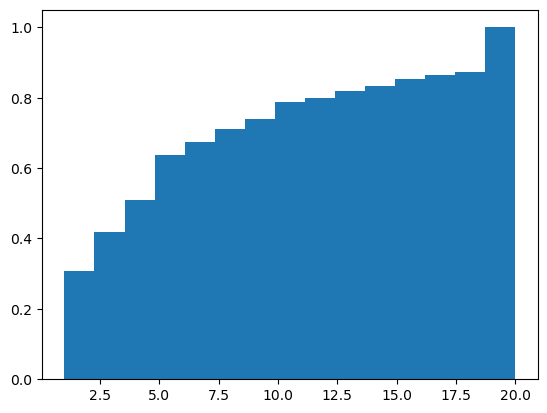

In [159]:
plt.hist(non_nicu_values_list,density=True,bins=MAX_METADATA_WINDOWS_NON_NICU,cumulative=True)

(array([0.03000075, 0.05250131, 0.02250056, 0.02250056, 0.01500038,
        0.03000075, 0.00750019, 0.03000075, 0.01500038, 0.03000075,
        0.00750019, 0.02250056, 0.03750094, 0.02250056, 0.02250056,
        0.02250056, 0.00750019, 0.00750019, 0.00750019, 0.02250056,
        0.        , 0.00750019, 0.00750019, 0.        , 0.        ,
        0.        , 0.01500038, 0.        , 0.        , 0.        ,
        0.02250056, 0.00750019, 0.00750019, 0.        , 0.00750019,
        0.00750019, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.00750019, 0.        , 0.        , 0.        ,
        0.00750019, 0.        , 0.        , 0.        , 0.00750019,
        0.        , 0.00750019, 0.        , 0.        , 0.        ,
        0.00750019, 0.        , 0.        , 0.00750019, 0.00750019,
        0.        , 0.        , 0.        , 0.00750019, 0.01500038,
        0.        , 0.        , 0.00750019, 0.        , 0.        ,
        0.00750019, 0.        , 0.00750019, 0.  

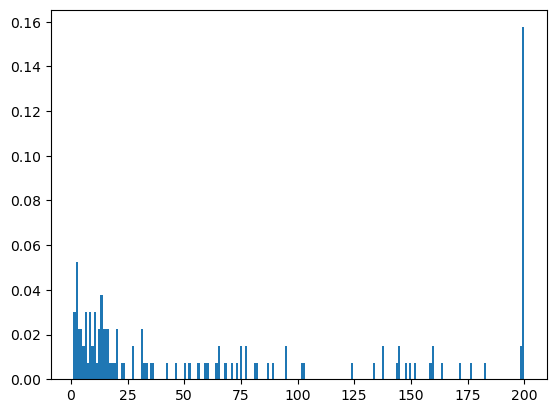

In [160]:
plt.hist(nicu_values_list,density=True,bins=MAX_METADATA_WINDOWS_NICU)

(array([0.24379973, 0.08560331, 0.07334733, 0.09993338, 0.03016857,
        0.02752882, 0.02432341, 0.03657939, 0.01037044, 0.01395296,
        0.01150177, 0.01640416, 0.00829636, 0.00659937, 0.1010647 ]),
 array([ 1.        ,  2.26666667,  3.53333333,  4.8       ,  6.06666667,
         7.33333333,  8.6       ,  9.86666667, 11.13333333, 12.4       ,
        13.66666667, 14.93333333, 16.2       , 17.46666667, 18.73333333,
        20.        ]),
 <BarContainer object of 15 artists>)

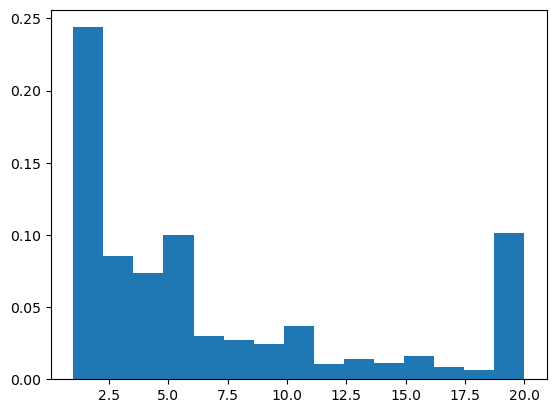

In [161]:
plt.hist(non_nicu_values_list,density=True,bins=MAX_METADATA_WINDOWS_NON_NICU)

### sample generation analysis 

In [162]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_with_chronos/sampled_windows_all_thresholds.pkl','rb') as f:
    df_sampled = pl.load(f)

In [163]:
df_sampled 

,mat_file,baby_id,window_start,window_end,baby_type,death_time,birth_time,label,threshold_days
0,./download/Vitals/NICU_1005_vitals.mat,NICU_1005_vitals,180.0,288180.0,NON_NICU,NaN,180.0,0.0,3
1,./download/Vitals/NICU_1005_vitals.mat,NICU_1005_vitals,1152180.0,1440180.0,NON_NICU,NaN,180.0,0.0,3
2,./download/Vitals/NICU_1005_vitals.mat,NICU_1005_vitals,2592180.0,2880180.0,NON_NICU,NaN,180.0,0.0,3
3,./download/Vitals/NICU_1005_vitals.mat,NICU_1005_vitals,4032180.0,4320180.0,NON_NICU,NaN,180.0,0.0,3
4,./download/Vitals/NICU_1005_vitals.mat,NICU_1005_vitals,5472180.0,5760180.0,NON_NICU,NaN,180.0,0.0,3
...,...,...,...,...,...,...,...,...,...
28681,./download/Vitals/NICU_8772_vitals.mat,NICU_8772_vitals,5482020.0,5770020.0,NICU,7862400.0,10020.0,0.0,7
28682,./download/Vitals/NICU_8772_vitals.mat,NICU_8772_vitals,5539620.0,5827620.0,NICU,7862400.0,10020.0,0.0,7
28683,./download/Vitals/NICU_8772_vitals.mat,NICU_8772_vitals,5597220.0,5885220.0,NICU,7862400.0,10020.0,0.0,7
28684,./download/Vitals/NICU_8772_vitals.mat,NICU_8772_vitals,5654820.0,5942820.0,NICU,7862400.0,10020.0,0.0,7


In [164]:
# what percentage of label 0 is from nicu and what from non nicu
# gives us an idnciation of how much more we need to geenrate from nicu or non nicu

In [165]:
df_sampled.groupby(['threshold_days','label']).size()

threshold_days  label
3               0.0      28052
                1.0        634
5               0.0      27716
                1.0        970
7               0.0      27435
                1.0       1251
dtype: int64

In [166]:
df_sampled[df_sampled["label"]==0 ].groupby(["threshold_days","baby_type"]).size()

threshold_days  baby_type
3               NICU          6029
                NON_NICU     22023
5               NICU          5693
                NON_NICU     22023
7               NICU          5412
                NON_NICU     22023
dtype: int64

In [ ]:
# within nicu, what is the compostion of label 0 and label 1
# gives us the indication of the samplign strategy, not the window strategy since we have that fixed and that will not alter basd on the label 1's we want

In [140]:
df_sampled[df_sampled["baby_type"]=="NICU" ].groupby(["threshold_days","label"]).size()

threshold_days  label
3               0.0      6029
                1.0       634
5               0.0      5693
                1.0       970
7               0.0      5412
                1.0      1251
dtype: int64

In [ ]:
# todo:
# have samplign anaylsis and window size analayasis 
# how many nicu and non nicu files have been covered 



In [ ]:
# compile your research notes and presentations till now 
# for each meeting, have an analysis report to see how you ended up with the results 
# compile the chnages, and results in the presentation